/Users/venkat/anaconda3/lib/python3.9/site-packages/scipy/optimize/_minpack_py.py:1010: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


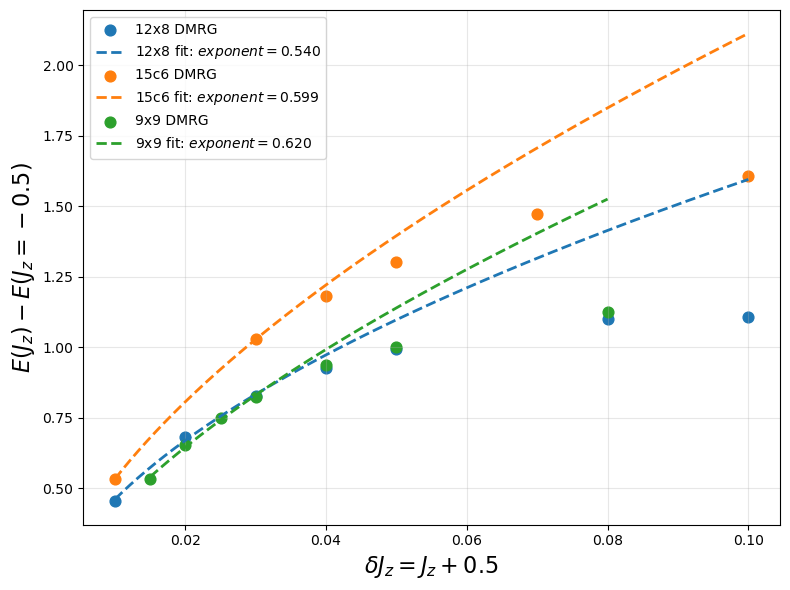



FIT SUMMARY
12x8       a = 5.52542617   b = 0.53973516
15c6       a = 8.38213423   b = 0.59857986
9x9        a = 7.30825882   b = 0.62048299


In [2]:
import numpy as np
import matplotlib.pyplot as pl
from scipy.optimize import curve_fit
from pathlib import Path


# ============================================================
# Main folder containing geometry folders:
# 12x8/
# 9x9/
# 15c6/
# etc.
# ============================================================

base_folder = Path("/Users/venkat/Desktop/polaron_figure/E_Jz/")


# ============================================================
# Fit function
#
# delta_E = a * (delta_Jz)^b
# ============================================================

def f(x, a, b):
    return a * x**b


# ============================================================
# Read final energy from one log file
# ============================================================

def get_last_energy(filepath):

    last_energy = None

    with open(filepath, "r") as file:
        for line in file:

            if "After sweep" in line and "energy" in line:

                temp = line.split("energy", 1)[1]

                last_energy = float(
                    temp.split("=", 1)[1]
                    .split()[0]
                    .rstrip(",")
                )

    return last_energy


# ============================================================
# Extract Jz from filename
#
# Example:
#
# out_12x8_1hole_Nup16_Jzm0p49.log
#
# gives
#
# Jz = -0.49
# ============================================================

def get_Jz(filename):

    Jz_text = filename.split("_Jz")[1].removesuffix(".log")

    Jz_text = (
        Jz_text
        .replace("m", "-")
        .replace("p", ".")
    )

    return float(Jz_text)


# ============================================================
# Dictionary where all results will be stored
# ============================================================

results = {}


# ============================================================
# Loop through all geometry folders
# ============================================================

for geometry_folder in sorted(base_folder.iterdir()):

    # Ignore files directly inside E_Jz
    if not geometry_folder.is_dir():
        continue

    geometry = geometry_folder.name

    # Get every .log file inside this geometry folder
    logfiles = list(geometry_folder.glob("*.log"))

    # Skip folders without log files
    if len(logfiles) == 0:
        continue


    #print("\n" + "=" * 60)
    #print(f"Processing geometry: {geometry}")
    #print("=" * 60)


    Jz_all = []
    energy_all = []


    # --------------------------------------------------------
    # Read every log file in this geometry
    # --------------------------------------------------------

    for logfile in logfiles:

        try:
            Jz = get_Jz(logfile.name)

        except Exception:
            print(f"Could not extract Jz from: {logfile.name}")
            continue


        E = get_last_energy(logfile)


        if E is None:
            print(f"No energy found in: {logfile.name}")
            continue


        Jz_all.append(Jz)
        energy_all.append(E)


    # Convert to numpy arrays
    Jz_all = np.array(Jz_all)
    energy_all = np.array(energy_all)


    # --------------------------------------------------------
    # Sort everything according to Jz
    # --------------------------------------------------------

    order = np.argsort(Jz_all)

    Jz_all = Jz_all[order]
    energy_all = energy_all[order]


    # --------------------------------------------------------
    # Find reference energy at Jz = -0.5
    # --------------------------------------------------------

    ref_mask = np.isclose(Jz_all, -0.5)


    if not np.any(ref_mask):

        print(
            f"WARNING: No Jz = -0.5 reference found "
            f"for {geometry}. Skipping."
        )

        continue


    reference = energy_all[ref_mask][0]


    # --------------------------------------------------------
    # Remove Jz = -0.5 from the regular data
    # --------------------------------------------------------

    non_ref_mask = ~ref_mask

    Jz_values = Jz_all[non_ref_mask]
    energies = energy_all[non_ref_mask]


    # --------------------------------------------------------
    # Define delta Jz and delta E
    # --------------------------------------------------------

    delta_Jz = Jz_values + 0.5
    delta_E = energies - reference


    # --------------------------------------------------------
    # FIT ONLY:
    #
    #       -0.5 < Jz <= -0.45
    #
    # So Jz = -0.42, -0.40, etc. are NOT used in the fit.
    # --------------------------------------------------------

    fit_mask = (
        (Jz_values > -0.5) &
        (Jz_values <= -0.47)
    )


    x_fit_data = delta_Jz[fit_mask]
    y_fit_data = delta_E[fit_mask]


    # Make sure there are enough points to fit
    if len(x_fit_data) < 2:

        print(
            f"WARNING: Not enough fitting points "
            f"for geometry {geometry}"
        )

        continue


    # --------------------------------------------------------
    # Perform power-law fit
    # --------------------------------------------------------

    popt, pcov = curve_fit(
        f,
        x_fit_data,
        y_fit_data,
        maxfev=10000
    )


    a, b = popt


    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    #print("All Jz values:")
    #print(Jz_values)

    #print("\nAll delta E:")
    #print(delta_E)

    #print("\nJz values USED IN FIT:")
    #print(Jz_values[fit_mask])

    #print("\ndelta E USED IN FIT:")
    #print(y_fit_data)

    #print(f"\nReference E(Jz=-0.5) = {reference}")

    #print(f"\nFit:")
    #print(f"a = {a:.10f}")
    #print(f"b = {b:.10f}")


    # --------------------------------------------------------
    # Store everything
    # --------------------------------------------------------

    results[geometry] = {

        # Raw values
        "Jz": Jz_values,
        "energy": energies,

        # Reference energy
        "reference": reference,

        # Shifted quantities
        "delta_Jz": delta_Jz,
        "delta_E": delta_E,

        # Points actually used for fitting
        "fit_Jz": Jz_values[fit_mask],
        "fit_delta_Jz": x_fit_data,
        "fit_delta_E": y_fit_data,

        # Fit information
        "popt": popt,
        "pcov": pcov,
        "a": a,
        "b": b
    }


# ============================================================
# Plot all geometries together
# ============================================================

fig, ax = pl.subplots(figsize=(8, 6))


for geometry, data in results.items():

    xdata = data["delta_Jz"]
    ydata = data["delta_E"]

    a = data["a"]
    b = data["b"]


    # --------------------------------------------------------
    # Plot ALL actual data points
    #
    # This includes -0.42, -0.40, etc.
    # even though those points were NOT fitted.
    # --------------------------------------------------------

    ax.scatter(
        xdata,
        ydata,
        s=60,
        label=f"{geometry} DMRG"
    )
    

    # --------------------------------------------------------
    # Plot fitted function across the ENTIRE available range
    #
    # So even though fitting only used data up to Jz=-0.45,
    # the fit curve is extrapolated to -0.42, -0.40, etc.
    # --------------------------------------------------------

    xfit = np.linspace(
        np.min(xdata),
        np.max(xdata),
        500
    )


    ax.plot(
        xfit,
        f(xfit, a, b),
        "--",
        linewidth=2,
        label=rf"{geometry} fit: $exponent={b:.3f}$"
    )


# ============================================================
# Plot formatting
# ============================================================

ax.set_xlabel(
    r"$\delta J_z = J_z + 0.5$",
    fontsize=16
)

ax.set_ylabel(
    r"$E(J_z)-E(J_z=-0.5)$",
    fontsize=16
)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.legend(
    fontsize=10
)

ax.grid(
    alpha=0.3
)

pl.tight_layout()

pl.show()


# ============================================================
# Print final summary of exponents
# ============================================================

print("\n")
print("=" * 60)
print("FIT SUMMARY")
print("=" * 60)

for geometry, data in results.items():

    print(
        f"{geometry:10s} "
        f"a = {data['a']:.8f}   "
        f"b = {data['b']:.8f}"
    )